<a id="phase-1"></a>

# 1. Business Understanding

Semesterprojekt SS 2026, HdM Stuttgart: die Nutzung des aktuellen Uhrenmodells klassifizieren.
Das Notebook zeigt Datenprüfung, Aufbereitung, Modellvergleich und abschließende Bewertung.
Label 1 bedeutet aktuelles, Label 0 älteres Modell. Auswahlmaß ist **Macro-F1**, ergänzt um **Accuracy**. Details: [Prozessübersicht](CRISP-DM-Prozessübersicht.md).


In [1]:
from pathlib import Path
import hashlib
import io
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGET = "User of latest model"
ID = "ID"
DATE = "Most current software update"
SPORT_HOURS = ["Swimming Hours per Week", "Biking Hours per Week", "Running Hours per Week"]
TOTAL_HOURS = "Total Training Hours per Week"
ROOT = Path.cwd()
TRAIN_FILE = ROOT / "data/triathlon_watch_training_data_final.csv"
TEST_FILE = ROOT / "data/triathlon_watch_test_data_final.csv"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})


<a id="phase-2"></a>

# 2. Data Understanding

Wir lesen die Originaldateien unverändert ein und untersuchen zunächst nur die Trainingsdatei.
Die Testdatei bleibt bis zur finalen Modellbewertung außerhalb der Modellwahl.


In [2]:
raw = pd.read_csv(TRAIN_FILE)
test = pd.read_csv(TEST_FILE)
assert list(raw.columns) == list(test.columns)
assert len(raw.columns) == 21
input_hashes = {path.name: hashlib.sha256(path.read_bytes()).hexdigest()
                for path in [TRAIN_FILE, TEST_FILE]}
print(f"Training: {raw.shape} | Gelieferter Test: {test.shape}")
display(raw.head(3))


Training: (1000, 21) | Gelieferter Test: (500, 21)


,ID,Age of customer,Sex,Ctry,Town,Swimming Hours per Week,Biking Hours per Week,Running Hours per Week,Total Training Hours per Week,VO2 Max,...,Calories Burned per Week,Support Cases of Customer,Customer Years,Most current software update,Goal of Training,Preferred Training Daytime,Subscription Type,Color of Watch,Synchronisation,User of latest model
0,C0001,61.0,Other,UK,Birmingham,2.52,0.10,1.78,4.40,23.08,...,2329.95,2.0,1.0,2024-07-22,Fitness,Evening,Free,White,Yes,1.0
1,C0003,57.0,Other,Australia,Sydney,1.55,10.01,4.57,16.13,39.04,...,7904.93,2.0,1.0,2024-05-11,Fitness,Evening,Premium,Black,Yes,0.0
2,C0004,30.0,Other,India,Bangalore,1.19,12.04,8.64,21.87,71.59,...,10839.81,2.0,0.0,2024-08-16,Competition,Afternoon,Free,White,Yes,1.0


In [3]:
overview = pd.DataFrame({
    "Datentyp": raw.dtypes.astype(str),
    "Fehlende Werte": raw.isna().sum(),
    "Eindeutige Werte": raw.nunique(),
})
display(overview)
display(pd.Series({
    "Vollständig leere Zeilen": raw.isna().all(axis=1).sum(),
    "Fehlende Labels": raw[TARGET].isna().sum(),
    "Kopierte gelabelte Zeilen, ohne ID": raw.dropna(subset=[TARGET]).drop(columns=ID).duplicated().sum(),
    "Doppelte vorhandene IDs": raw[ID].dropna().duplicated().sum(),
}, name="Anzahl").to_frame())


,Datentyp,Fehlende Werte,Eindeutige Werte
ID,str,22,971
Age of customer,float64,22,48
Sex,str,22,3
Ctry,str,22,7
Town,str,61,15
Swimming Hours per Week,float64,22,440
Biking Hours per Week,float64,46,649
Running Hours per Week,float64,22,542
Total Training Hours per Week,float64,22,732
VO2 Max,float64,25,858


,Anzahl
Vollständig leere Zeilen,21
Fehlende Labels,22
"Kopierte gelabelte Zeilen, ohne ID",2
Doppelte vorhandene IDs,7


In [4]:
numeric_columns = raw.select_dtypes(include="number").columns.drop(TARGET)
display(raw[numeric_columns].describe().T)
display(raw[TARGET].value_counts(dropna=False).rename("Label-Häufigkeit").to_frame())
display(raw["Ctry"].value_counts(dropna=False).rename("Länderwerte").to_frame())
negative_counts = (raw[numeric_columns] < 0).sum()
display(negative_counts[negative_counts > 0].rename("Negative Werte").to_frame())

def inconsistent_hours(frame):
    complete = frame[SPORT_HOURS + [TOTAL_HOURS]].notna().all(axis=1)
    difference = frame[TOTAL_HOURS] - frame[SPORT_HOURS].sum(axis=1)
    return complete & (difference.abs() > 0.03)

hour_issues = inconsistent_hours(raw)
print("Gesamtstunden widersprechen der Summe der drei Sportarten:", hour_issues.sum())
display(raw.loc[hour_issues, [ID] + SPORT_HOURS + [TOTAL_HOURS]])


,count,mean,std,min,25%,50%,75%,max
Age of customer,978.0,40.529652,14.072180,-1.00,29.0000,41.000,53.0000,64.0000
Swimming Hours per Week,978.0,2.226196,1.595254,0.00,1.0200,2.020,3.1875,9.9700
Biking Hours per Week,954.0,5.529109,3.499372,0.00,2.7675,5.110,7.8700,16.1100
Running Hours per Week,978.0,3.262219,2.165709,0.00,1.6350,2.930,4.6000,11.8700
Total Training Hours per Week,978.0,11.446155,8.038531,0.15,7.3800,10.220,14.0975,100.0000
VO2 Max,975.0,51.374066,21.459113,10.22,42.0700,53.400,60.0950,247.2578
10k Running Time Prediction,978.0,45.610521,7.549771,29.12,40.3025,43.885,50.2575,67.0600
Calories Burned per Week,959.0,5487.534849,2499.741648,-47.26,3661.9400,5168.410,7000.8400,13280.0600
Support Cases of Customer,978.0,1.956033,1.413167,0.00,1.0000,2.000,3.0000,4.0000
Customer Years,978.0,3.792434,2.916593,0.00,1.0000,3.000,6.0000,11.0000


,Label-Häufigkeit
User of latest model,
0.0,573
1.0,405
NaN,22


,Länderwerte
Ctry,
Australia,200
USA,199
UK,191
India,186
Germany,179
NaN,22
Germayn,19
UnknownLand,4


,Negative Werte
Age of customer,10
Calories Burned per Week,2


Gesamtstunden widersprechen der Summe der drei Sportarten: 5


,ID,Swimming Hours per Week,Biking Hours per Week,Running Hours per Week,Total Training Hours per Week
74,C0071,2.75,6.61,1.57,100.0
184,C0185,0.89,6.43,3.28,100.0
250,C0249,2.24,3.66,7.24,100.0
649,C0644,6.98,7.09,7.17,100.0
929,C0932,1.10,13.54,8.76,100.0


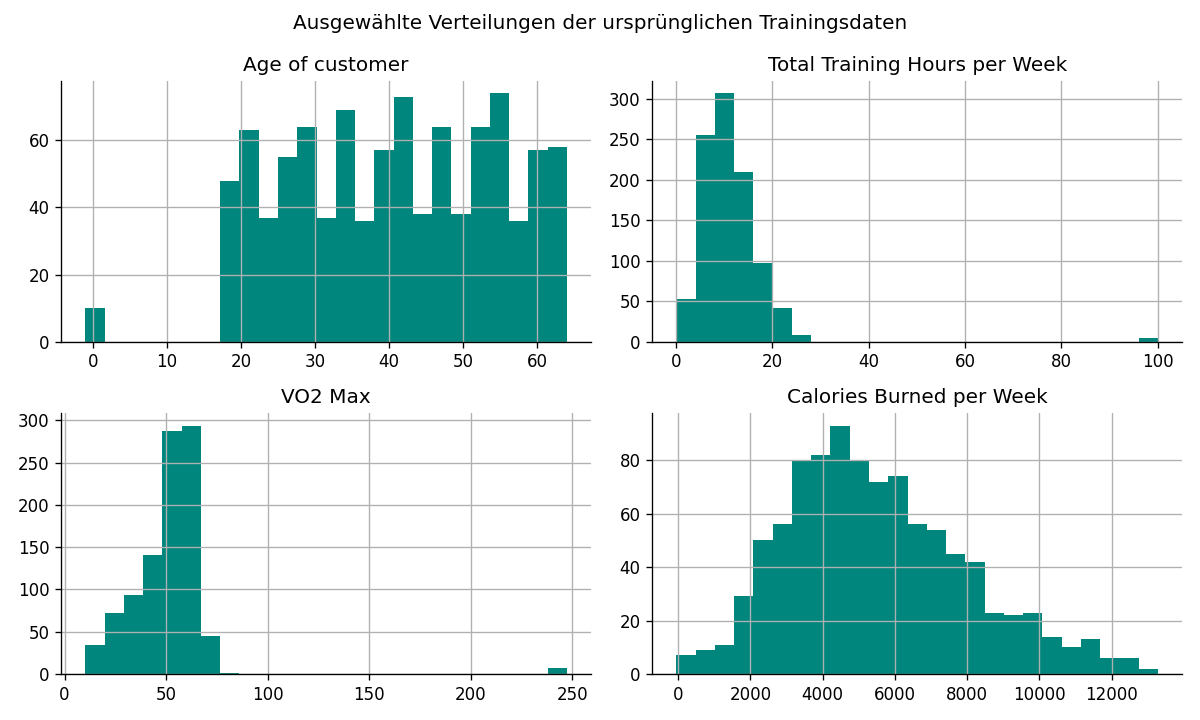

In [5]:
def show_figure(figure):
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=120)
    display(Image(data=buffer.getvalue()))
    plt.close(figure)

plot_columns = ["Age of customer", "Total Training Hours per Week",
                "VO2 Max", "Calories Burned per Week"]
raw[plot_columns].hist(bins=25, figsize=(10, 6), color="#00867D")
plt.suptitle("Ausgewählte Verteilungen der ursprünglichen Trainingsdaten")
plt.tight_layout()
show_figure(plt.gcf())


In [6]:
shared_ids = set(raw[ID].dropna()) & set(test[ID].dropna())
print(f"Gemeinsame Kennungen beider Dateien: {len(shared_ids)}")


Gemeinsame Kennungen beider Dateien: 465


Die 465 gemeinsamen IDs könnten dieselben Kunden oder neu vergebene Kennungen bezeichnen.
Wir dokumentieren diese Unsicherheit; der spätere Kurs-Testwert ist deshalb kein uneingeschränkter externer Leistungsnachweis.


<a id="phase-3"></a>

# 3. Data Preparation

Fehlende Labels und kopierte Trainingsbeobachtungen werden entfernt. Danach trennen wir
Training und Validation nach IDs. Die Bewertungszeilen und ihre Labels bleiben bei allen Varianten gleich.


In [7]:
data = raw.dropna(subset=[TARGET]).copy()
data = data.drop_duplicates(subset=[column for column in data if column != ID])
assert data[TARGET].isin([0, 1]).all()
assert data[ID].notna().all()

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_index, val_index = next(splitter.split(data, groups=data[ID]))
train = data.iloc[train_index].copy()
validation = data.iloc[val_index].copy()
y_train = train[TARGET].astype(int)
y_val = validation[TARGET].astype(int)
groups_train = train[ID]
assert set(train[ID]).isdisjoint(set(validation[ID]))
assert y_train.nunique() == y_val.nunique() == 2
print(f"Gelabelt ohne Kopien: {len(data)} | Training: {len(train)} | Validation: {len(validation)}")


Gelabelt ohne Kopien: 976 | Training: 780 | Validation: 196


**Feste Regeln:** ID entfernen und Datum als Tagesoffset darstellen. Die bereinigte Variante
korrigiert Länderwerte und ersetzt ungültige Zahlen durch fehlende Werte. Wir nehmen an,
dass die Gesamtstunden die drei Sportarten summieren; widersprüchliche Gesamtwerte werden ebenfalls imputiert.


In [8]:
def make_features(frame, clean=False):
    X = frame.drop(columns=[ID, TARGET]).copy()
    dates = pd.to_datetime(X.pop(DATE), format="%Y-%m-%d", errors="coerce")
    X["Update day offset"] = (dates - pd.Timestamp("2024-01-01")).dt.days
    if clean:
        X["Ctry"] = X["Ctry"].replace({"Germayn": "Germany", "UnknownLand": np.nan})
        numeric = X.select_dtypes(include="number").columns.drop("Update day offset")
        X[numeric] = X[numeric].mask(X[numeric] < 0)
        hours = [column for column in X if "Hours per Week" in column]
        X[hours] = X[hours].mask(X[hours] > 168)
        X.loc[inconsistent_hours(X), TOTAL_HOURS] = np.nan
    for column in X.select_dtypes(exclude="number"):
        X[column] = X[column].astype(object)
    return X

sample_features = make_features(train)
num_columns = sample_features.select_dtypes(include="number").columns.tolist()
cat_columns = sample_features.select_dtypes(exclude="number").columns.tolist()
print(f"Modelleingaben: {len(num_columns)} numerisch, {len(cat_columns)} kategorial")


Modelleingaben: 11 numerisch, 8 kategorial


Imputation, Skalierung und Kodierung stehen gemeinsam mit dem Modell in einer Pipeline.
So lernt auch die spätere Kreuzvalidierung diese Schritte ausschließlich aus dem jeweiligen Trainingsfold.


In [9]:
def make_pipeline(classifier, strategy="median", scale=True, select=False):
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy=strategy, keep_empty_features=True)),
        ("scale", StandardScaler() if scale else "passthrough"),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    preprocessing = ColumnTransformer([
        ("numeric", numeric, num_columns),
        ("categorical", categorical, cat_columns),
    ])
    selection = SelectFromModel(RandomForestClassifier(
        n_estimators=100, random_state=SEED, n_jobs=1), threshold="median") if select else "passthrough"
    return Pipeline([("prepare", preprocessing), ("select", selection), ("model", clone(classifier))])


In [10]:
def evaluate_model(model, X_train, y_train, X_val, y_val):
    train_prediction = model.predict(X_train)
    val_prediction = model.predict(X_val)
    train_f1 = f1_score(y_train, train_prediction, average="macro", zero_division=0)
    val_f1 = f1_score(y_val, val_prediction, average="macro", zero_division=0)
    return {
        "Accuracy Training": accuracy_score(y_train, train_prediction),
        "Accuracy Validation": accuracy_score(y_val, val_prediction),
        "F1 Training": train_f1, "F1 Validation": val_f1,
        "F1-Abstand": train_f1 - val_f1,
    }


**Logistische Ausgangsbaseline:** Wir verändern jeweils die Vorbereitung bei gleichem Algorithmus
und denselben Validierungszeilen. Die erste Variante verwendet Mittelwert-Imputation und keine Skalierung.


In [11]:
logistic = LogisticRegression(solver="liblinear", max_iter=2000, random_state=SEED)
preparations = {
    "Minimal": ("mean", False, False),
    "Median": ("median", False, False),
    "Bereinigt": ("median", True, False),
    "Bereinigt + skaliert": ("median", True, True),
}
preparation_rows = []
for name, (strategy, clean, scale) in preparations.items():
    X_train = make_features(train, clean=clean)
    X_val = make_features(validation, clean=clean)
    model = make_pipeline(logistic, strategy=strategy, scale=scale)
    model.fit(X_train, y_train)
    scores = evaluate_model(model, X_train, y_train, X_val, y_val)
    preparation_rows.append({"Variante": name, **scores})
preparation_results = pd.DataFrame(preparation_rows)
baseline_f1 = preparation_results.iloc[0]["F1 Validation"]
preparation_results["Delta F1 zur Baseline"] = preparation_results["F1 Validation"] - baseline_f1
preparation_results["Delta Accuracy zur Baseline"] = (
    preparation_results["Accuracy Validation"] - preparation_results.iloc[0]["Accuracy Validation"])
preparation_results["Relative F1-Änderung (%)"] = (
    100 * preparation_results["Delta F1 zur Baseline"] / baseline_f1)
display(preparation_results.round(3))


,Variante,Accuracy Training,Accuracy Validation,F1 Training,F1 Validation,F1-Abstand,Delta F1 zur Baseline,Delta Accuracy zur Baseline,Relative F1-Änderung (%)
0,Minimal,0.808,0.740,0.798,0.732,0.066,0.000,0.000,0.000
1,Median,0.806,0.745,0.797,0.738,0.059,0.006,0.005,0.779
2,Bereinigt,0.796,0.755,0.786,0.748,0.038,0.016,0.015,2.211
3,Bereinigt + skaliert,0.797,0.755,0.788,0.748,0.039,0.016,0.015,2.211


Vorbereitung für den Modellvergleich: Bereinigt


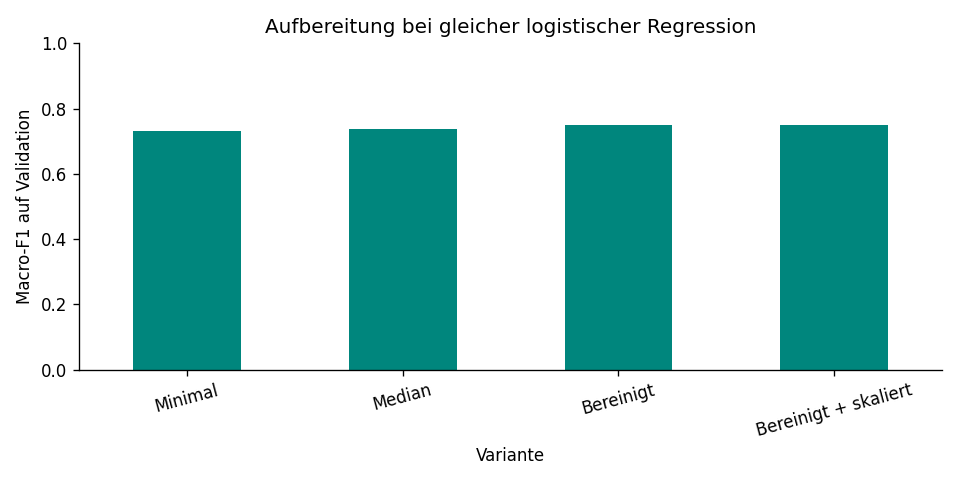

In [12]:
best_preparation = preparation_results.loc[preparation_results["F1 Validation"].idxmax(), "Variante"]
strategy, clean, scale = preparations[best_preparation]
X_train = make_features(train, clean=clean)
X_val = make_features(validation, clean=clean)
print("Vorbereitung für den Modellvergleich:", best_preparation)

axis = preparation_results.plot.bar(x="Variante", y="F1 Validation", legend=False,
                                    ylim=(0, 1), rot=15, color="#00867D", figsize=(8, 4))
axis.set_title("Aufbereitung bei gleicher logistischer Regression")
axis.set_ylabel("Macro-F1 auf Validation")
plt.tight_layout()
show_figure(axis.figure)


<a id="phase-4"></a>

# 4. Modeling

Wir vergleichen drei Modellfamilien mit derselben Vorbereitung. Danach prüfen wir Feature Selection
und stimmen die zwei stärksten Familien mit einem kleinen Suchraum ab. Bewertungsmaß bleibt Macro-F1.


In [13]:
models = {
    "Logistische Regression": logistic,
    "Entscheidungsbaum": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1),
}
model_rows = []
fitted_models = {}
for name, classifier in models.items():
    model = make_pipeline(classifier, strategy=strategy, scale=scale)
    model.fit(X_train, y_train)
    scores = evaluate_model(model, X_train, y_train, X_val, y_val)
    model_rows.append({"Modell": name, "Stufe": "Baseline", **scores})
    fitted_models[(name, "Baseline")] = model


**Feature Selection:** Ein Random Forest behält kodierte Merkmale mit mindestens medianer Importance.
Der Selektor wird gemeinsam mit der Pipeline trainiert; wir prüfen auch mögliche Verschlechterungen.


In [14]:
selection_rows = []
for name, classifier in models.items():
    model = make_pipeline(classifier, strategy=strategy, scale=scale, select=True)
    model.fit(X_train, y_train)
    scores = evaluate_model(model, X_train, y_train, X_val, y_val)
    model_rows.append({"Modell": name, "Stufe": "Feature Selection", **scores})
    fitted_models[(name, "Feature Selection")] = model
    selected = model.named_steps["select"].get_support()
    selection_rows.append({"Modell": name, "Kodierte Spalten": len(selected),
                           "Beibehalten": int(selected.sum())})
display(pd.DataFrame(selection_rows))


,Modell,Kodierte Spalten,Beibehalten
0,Logistische Regression,47,24
1,Entscheidungsbaum,47,24
2,Random Forest,47,24


**Tuning:** Drei Gruppenfolds innerhalb des Trainingssatzes; Auswahl der Modellfamilien anhand der Validation.
Feature Selection wird innerhalb der Suche erneut je Trainingsfold gelernt.


In [15]:
parameter_grids = {
    "Logistische Regression": {"model__C": [0.1, 1.0, 10.0], "model__class_weight": [None, "balanced"]},
    "Entscheidungsbaum": {"model__max_depth": [3, 5, None], "model__min_samples_leaf": [1, 5]},
    "Random Forest": {"model__max_depth": [5, None], "model__min_samples_leaf": [1, 5]},
}
family_scores = pd.DataFrame(model_rows).groupby("Modell")["F1 Validation"].max()
top_families = family_scores.nlargest(2).index
cv = GroupKFold(n_splits=3)
for name in top_families:
    selector = SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1), threshold="median")
    parameters = {**parameter_grids[name], "select": ["passthrough", selector]}
    pipeline = make_pipeline(models[name], strategy=strategy, scale=scale)
    search = GridSearchCV(pipeline, parameters, scoring="f1_macro", cv=cv, n_jobs=1, error_score="raise")
    search.fit(X_train, y_train, groups=groups_train)
    model = search.best_estimator_
    model_rows.append({"Modell": name, "Stufe": "Tuning", **evaluate_model(model, X_train, y_train, X_val, y_val)})
    fitted_models[(name, "Tuning")] = model
    print(name, {key: value for key, value in search.best_params_.items() if key != "select"})
    print("Feature Selection:", search.best_params_["select"] != "passthrough")


Logistische Regression {'model__C': 0.1, 'model__class_weight': None}
Feature Selection: False


Random Forest {'model__max_depth': None, 'model__min_samples_leaf': 1}
Feature Selection: False


,Modell,Stufe,Accuracy Training,Accuracy Validation,F1 Training,F1 Validation,F1-Abstand
3,Logistische Regression,Feature Selection,0.797,0.760,0.787,0.754,0.033
6,Logistische Regression,Tuning,0.805,0.760,0.794,0.752,0.042
0,Logistische Regression,Baseline,0.796,0.755,0.786,0.748,0.038
2,Random Forest,Baseline,1.000,0.745,1.000,0.735,0.265
7,Random Forest,Tuning,1.000,0.745,1.000,0.735,0.265
5,Random Forest,Feature Selection,1.000,0.740,1.000,0.728,0.272
4,Entscheidungsbaum,Feature Selection,1.000,0.653,1.000,0.646,0.354
1,Entscheidungsbaum,Baseline,1.000,0.622,1.000,0.617,0.383


Gewählt auf dem festen Split: Logistische Regression | Feature Selection


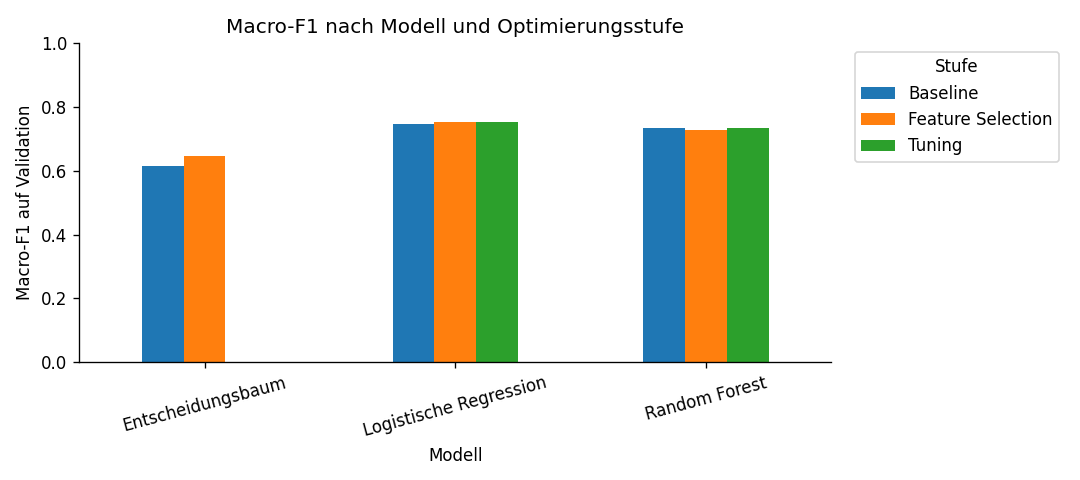

In [16]:
model_results = pd.DataFrame(model_rows)
ranking = model_results.sort_values(["F1 Validation", "Accuracy Validation"], ascending=False, kind="stable")
display(ranking.round(3))
best = ranking.iloc[0]
best_model = fitted_models[(best["Modell"], best["Stufe"])]
print("Gewählt auf dem festen Split:", best["Modell"], "|", best["Stufe"])

comparison = model_results.pivot(index="Modell", columns="Stufe", values="F1 Validation")
axis = comparison.plot.bar(ylim=(0, 1), rot=15, figsize=(9, 4))
axis.legend(title="Stufe", loc="upper left", bbox_to_anchor=(1.02, 1))
axis.set_title("Macro-F1 nach Modell und Optimierungsstufe")
axis.set_ylabel("Macro-F1 auf Validation")
plt.tight_layout()
show_figure(axis.figure)


**Sensitivität:** Fünf Gruppensplits vergleichen die beiden Ausgangsmodelle bei festgehaltener Aufbereitung.
Die Prüfung wiederholt nicht das gesamte Auswahlverfahren und ändert unsere Modellwahl nicht.


In [17]:
stability_rows = []
for split_seed in [7, 21, 42, 84, 123]:
    split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=split_seed)
    a, b = next(split.split(data, groups=data[ID]))
    split_train, split_val = data.iloc[a], data.iloc[b]
    assert set(split_train[ID]).isdisjoint(set(split_val[ID]))
    for name in ["Logistische Regression", "Random Forest"]:
        candidate = clone(fitted_models[(name, "Baseline")])
        candidate.fit(make_features(split_train, clean=clean), split_train[TARGET].astype(int))
        prediction = candidate.predict(make_features(split_val, clean=clean))
        stability_rows.append({"Seed": split_seed, "Modell": name,
                               "Macro-F1": f1_score(split_val[TARGET].astype(int), prediction, average="macro")})
stability_results = pd.DataFrame(stability_rows).pivot(index="Seed", columns="Modell", values="Macro-F1")
display(stability_results.round(3))


Modell,Logistische Regression,Random Forest
Seed,,
7,0.753,0.793
21,0.729,0.751
42,0.748,0.735
84,0.757,0.763
123,0.760,0.768


<a id="phase-5"></a>

# 5. Evaluation

Die Modellentscheidung steht fest. Wir trainieren diese Konfiguration auf Training plus Validation
und bewerten sie anschließend auf allen 500 Zeilen der gelieferten Kurs-Testdatei.


In [18]:
X_development = make_features(data, clean=clean)
y_development = data[TARGET].astype(int)
X_test = make_features(test, clean=clean)
assert test[TARGET].notna().all() and test[TARGET].isin([0, 1]).all()
y_test = test[TARGET].astype(int)

final_model = clone(best_model)
final_model.fit(X_development, y_development)
final_prediction = final_model.predict(X_test)
test_accuracy = accuracy_score(y_test, final_prediction)
test_f1 = f1_score(y_test, final_prediction, average="macro", zero_division=0)
display(pd.DataFrame({
    "Accuracy": [best["Accuracy Validation"], test_accuracy],
    "Macro-F1": [best["F1 Validation"], test_f1],
}, index=["Validation vor Refitting", "Gelieferter Kurs-Test"]).round(3))


,Accuracy,Macro-F1
Validation vor Refitting,0.76,0.754
Gelieferter Kurs-Test,0.79,0.780


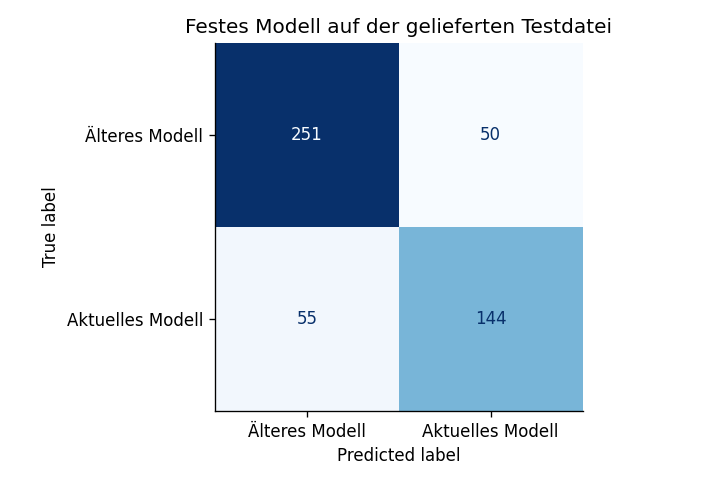

              precision    recall  f1-score   support

           0       0.82      0.83      0.83       301
           1       0.74      0.72      0.73       199

    accuracy                           0.79       500
   macro avg       0.78      0.78      0.78       500
weighted avg       0.79      0.79      0.79       500



**Fehlerbild:** 55 von 199 Nutzern des aktuellen Modells werden als Nutzer eines älteren Modells eingeordnet (**27.6%**).

In [19]:
figure, axis = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_predictions(y_test, final_prediction, labels=[0, 1],
    display_labels=["Älteres Modell", "Aktuelles Modell"], cmap="Blues", colorbar=False, ax=axis)
axis.set_title("Festes Modell auf der gelieferten Testdatei")
plt.tight_layout()
show_figure(figure)
print(classification_report(y_test, final_prediction, labels=[0, 1], zero_division=0))

missed_latest = int(((y_test == 1) & (final_prediction == 0)).sum())
actual_latest = int((y_test == 1).sum())
display(Markdown(
    f"**Fehlerbild:** {missed_latest} von {actual_latest} Nutzern des aktuellen Modells "
    f"werden als Nutzer eines älteren Modells eingeordnet "
    f"(**{missed_latest / actual_latest:.1%}**)."
))


Die Modellwahl gilt für den festen Split; die Sensitivitätsprüfung belegt keine allgemeine Überlegenheit.
Der bereits ausgewertete Kurs-Test ist kein neuer unabhängiger Test. ID-Überschneidungen und ungeklärte
Merkmalszeitpunkte begrenzen die Aussagekraft; zukünftige Käufe und kausale Wirkungen werden nicht vorhergesagt.


In [20]:
best_preparation_f1 = preparation_results["F1 Validation"].max()
display(Markdown(
    f"**Ergebnis:** {best['Modell']} ({best['Stufe']}). "
    f"Aufbereitung: {best_preparation}. "
    f"Macro-F1 der logistischen Ausgangsbaseline: **{baseline_f1:.3f}**; "
    f"beste Aufbereitung: **{best_preparation_f1:.3f}**. "
    f"Gelieferter Kurs-Test: Accuracy **{test_accuracy:.3f}**, Macro-F1 **{test_f1:.3f}**."
))


**Ergebnis:** Logistische Regression (Feature Selection). Aufbereitung: Bereinigt. Macro-F1 der logistischen Ausgangsbaseline: **0.732**; beste Aufbereitung: **0.748**. Gelieferter Kurs-Test: Accuracy **0.790**, Macro-F1 **0.780**.

<a id="phase-6"></a>

# 6. Deployment

Die Übergabe besteht aus Notebook, README und [Prozessübersicht mit D2](CRISP-DM-Prozessübersicht.md).
Zur Reproduktion: Repository als Arbeitsverzeichnis, `.venv` als Kernel und alle Zellen von oben ausführen.


In [21]:
assert len(X_test) == len(test) == 500
assert set(train[ID]).isdisjoint(set(validation[ID]))
for path in [TRAIN_FILE, TEST_FILE]:
    assert hashlib.sha256(path.read_bytes()).hexdigest() == input_hashes[path.name]

print("Originaldateien unverändert; alle Testzeilen erhalten; interne Gruppen getrennt.")
display(pd.Series(input_hashes, name="SHA-256").rename_axis("Datei").to_frame())
display(pd.Series({package: version(package) for package in
    ["numpy", "pandas", "scikit-learn", "matplotlib", "ipykernel"]}, name="Version").to_frame())
print("Python:", platform.python_version())


Originaldateien unverändert; alle Testzeilen erhalten; interne Gruppen getrennt.


,SHA-256
Datei,
triathlon_watch_training_data_final.csv,2dc7199529804a1ef6c3e78b1ce709fa4b70ffcb0fef6c...
triathlon_watch_test_data_final.csv,a18dbf03ae85ea018f9730a74182e9c7f6f28e79b0da1e...


,Version
numpy,2.4.6
pandas,3.0.3
scikit-learn,1.9.0
matplotlib,3.10.9
ipykernel,7.2.0


Python: 3.14.4
